# Practical 6: K-Means Clustering — Easy Exam Version

**Aim:** Apply K-Means to `sales_data_sample.csv` and find a suitable number of clusters using the elbow method.

**Before running:** Download the [Kaggle sales dataset](https://www.kaggle.com/datasets/kyanyoga/sample-sales-data), extract `sales_data_sample.csv`, and place it in the same folder as this notebook. Install packages if needed: `pip install pandas matplotlib scikit-learn`. Run the code, inspect the elbow graph, change `k = 3` to your chosen elbow value, and run again.

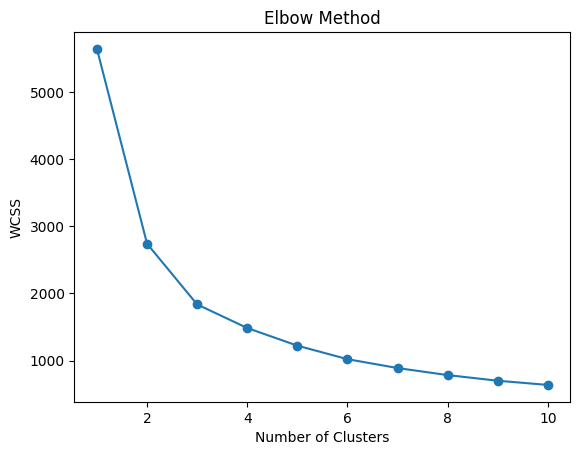

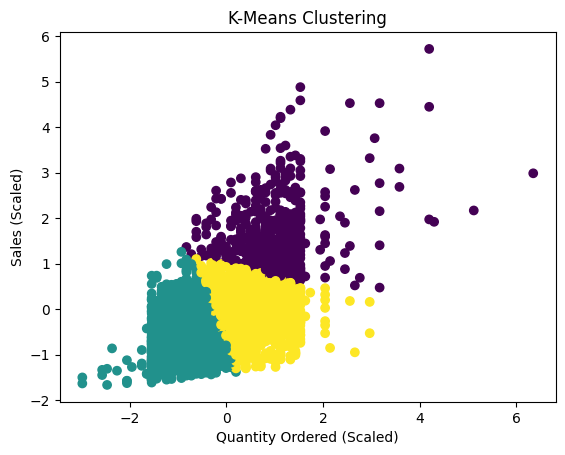

Number of clusters: 3


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

# Read dataset and select two features
data = pd.read_csv("sales_data_sample.csv", encoding="latin1")
X = data[["QUANTITYORDERED", "SALES"]].dropna()
X = StandardScaler().fit_transform(X)

# Elbow method
wcss = []
for i in range(1, 11):
    model = KMeans(n_clusters=i, random_state=42, n_init=10)
    model.fit(X)
    wcss.append(model.inertia_)

plt.plot(range(1, 11), wcss, marker="o")
plt.xlabel("Number of Clusters")
plt.ylabel("WCSS")
plt.title("Elbow Method")
plt.show()

# Change 3 to the elbow value seen in the graph
k = 3
model = KMeans(n_clusters=k, random_state=42, n_init=10)
labels = model.fit_predict(X)

plt.scatter(X[:, 0], X[:, 1], c=labels, cmap="viridis")
plt.xlabel("Quantity Ordered (Scaled)")
plt.ylabel("Sales (Scaled)")
plt.title("K-Means Clustering")
plt.show()
print("Number of clusters:", k)


## Simple explanation

1. **Read:** Load the sales CSV.
2. **Select:** Use quantity ordered and sales amount.
3. **Scale:** Make their ranges comparable.
4. **Elbow:** Try 1–10 clusters and plot WCSS.
5. **Cluster:** Set `k` from the bend in the elbow plot.
6. **Plot:** Show the groups in different colors.

**Viva:** K-Means is unsupervised learning. WCSS is within-cluster sum of squares. The elbow is where further clusters give diminishing improvements. `fit_predict()` fits the model and assigns a cluster label to each row.

**Note:** The correct k depends on the plotted results; 3 is only a starting example.